In [1]:
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library
import xarray as xr # Libary to work with labeled n-dimensional data
import dask # Distributed data libary
import dask.distributed
import multiprocessing
from dask.diagnostics import ProgressBar
import glob, os
from matplotlib.lines import Line2D

from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter1d
from subprocess import run, PIPE
import sys
import os
from sklearn.neighbors import KernelDensity
import gc
from concurrent.futures import ProcessPoolExecutor
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')
dask.config.config.get('distributed').get('dashboard').update({'link':'{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'})
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator, NearestNDInterpolator

In [2]:
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib import pyplot as plt # Standard Plotting library
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from cartopy import crs as ccrs # Cartography library
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import matplotlib.tri as tri

In [3]:
#'''Provides information about the CPU and starts the dask client'''
ncpu = multiprocessing.cpu_count()
processes = False
nworker = 1
threads = ncpu // nworker
print(f"Number of CPUs: {ncpu}, number of threads: {threads}, number of workers: {nworker}, processes: {processes}")
client = Client(processes=processes,
 threads_per_worker=threads,
 n_workers=nworker,
 memory_limit='1000GB'
 )

Number of CPUs: 64, number of threads: 64, number of workers: 1, processes: False


In [4]:
latitude = [30,60]


In [5]:
ifs_on = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/ifs_2.8km_on_30-60N_markov.nc')[['P_WW','P_WD','P_DW','P_DD']]

ifs_off = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/ifs_2.8km_off_30-60N_markov.nc')[['P_WW','P_WD','P_DW','P_DD']]
ifs_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/ifs_cycle3_30-60N_markov.nc')[['P_WW','P_WD','P_DW','P_DD']]
ifs_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/ifs_cycle4_1990-2020_30-60N_markov.nc')[['P_WW','P_WD','P_DW','P_DD']]
icon_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/icon_cycle3_30-60N_markov.nc')[['P_WW','P_WD','P_DW','P_DD']]
icon_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/icon_cycle4_30-60N_markov.nc')[['P_WW','P_WD','P_DW','P_DD']]
cesm2 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/cesm2_1850-2014_ens_30-60N_markov.nc')[['P_WW','P_WD','P_DW','P_DD']]
imerg = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/imerg_30-60N_markov.nc')[['P_WW','P_WD','P_DW','P_DD']]

icon_cycle4 = icon_cycle4.isel(year=slice(0,5))



In [6]:
land_sea_ifs_high = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_2.8km_deep_off/ifs_hpx2048_lsm_30-60N.nc')['lsm']
land_sea_ifs_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_4.4-FESOM_5/IFS_cycle3_lsm_30-60N.nc')['lsm']
land_sea_ifs_zoom9 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_zoom9/30-60N_ifs_hpx512_lsm.nc')['lsm']
land_sea_icon_zoom10 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/ICON_zoom10/icon_cycle3_lsm_30-60N.nc')['ocean_fraction_surface']
land_sea_icon_zoom9 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/ICON_zoom9/30-60N_ICON_ngc4008_ocean_fraction_surface_zoom9.nc')['ocean_fraction_surface']
land_sea_imerg = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/IMERG/clean/30-60N_fixgrid_GPM_IMERG_LandSeaMask.2.nc4')['landseamask']
land_sea_imerg = land_sea_imerg.assign_coords(lat=imerg.lat, lon=imerg.lon)
land_sea_cesm2 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/CESM2/precip/24H/mask.nc')['MASK']
land_sea_cesm2 = land_sea_cesm2[0,:,:]
indexer = ((land_sea_cesm2.lat>=latitude[0]) & (land_sea_cesm2.lat<=latitude[1]))
land_sea_cesm2 = land_sea_cesm2.where(indexer,drop=True)
land_sea_cesm2 = land_sea_cesm2.assign_coords(lat=cesm2.lat, lon=cesm2.lon)

ifs_on_land = ifs_on.where(land_sea_ifs_high > 0, np.nan)
ifs_off_land = ifs_off.where(land_sea_ifs_high > 0, np.nan)
ifs_cycle3_land = ifs_cycle3.where(land_sea_ifs_cycle3 > 0, np.nan)
ifs_cycle4_land = ifs_cycle4.where(land_sea_ifs_zoom9 > 0, np.nan)
icon_cycle3_land = icon_cycle3.where(land_sea_icon_zoom10 < 1, np.nan)
icon_cycle4_land = icon_cycle4.where(land_sea_icon_zoom9 < 1, np.nan)
imerg_land = imerg.where(land_sea_imerg < 100, np.nan)
cesm2_land = cesm2.where(land_sea_cesm2 > 0, np.nan)


In [7]:
ifs_cycle3_land = ifs_cycle3_land.stack(sample=("year", "value"))
ifs_cycle4_land = ifs_cycle4_land.stack(sample=("year", "value"))
icon_cycle3_land = icon_cycle3_land.stack(sample=("year", "cell"))
icon_cycle4_land = icon_cycle4_land.stack(sample=("year", "cell"))
imerg_land = imerg_land.stack(sample=("year", "lat", "lon"))
cesm2_land = cesm2_land.stack(sample=("member", "year", "lat", "lon"))


In [8]:
ifs_on_land = ifs_on_land * 100
ifs_off_land = ifs_off_land * 100
ifs_cycle3_land = ifs_cycle3_land * 100 
ifs_cycle4_land = ifs_cycle4_land * 100
icon_cycle3_land = icon_cycle3_land * 100
icon_cycle4_land = icon_cycle4_land * 100
imerg_land = imerg_land * 100
cesm2_land = cesm2_land * 100

In [9]:
ifs_on_land_WW = ifs_on_land.P_WW.where(~ifs_on_land.P_WW.isnull(), drop=True)
ifs_off_land_WW = ifs_off_land.P_WW.where(~ifs_off_land.P_WW.isnull(), drop=True)
ifs_cycle3_land_WW = ifs_cycle3_land.P_WW.where(~ifs_cycle3_land.P_WW.isnull(), drop=True)
ifs_cycle4_land_WW = ifs_cycle4_land.P_WW.where(~ifs_cycle4_land.P_WW.isnull(), drop=True)
icon_cycle3_land_WW = icon_cycle3_land.P_WW.where(~icon_cycle3_land.P_WW.isnull(), drop=True)
icon_cycle4_land_WW = icon_cycle4_land.P_WW.where(~icon_cycle4_land.P_WW.isnull(), drop=True)
imerg_land_WW = imerg_land.P_WW.where(~imerg_land.P_WW.isnull(), drop=True)
cesm2_land_WW = cesm2_land.P_WW.where(~cesm2_land.P_WW.isnull(), drop=True)


In [10]:
ifs_on_land_WD = ifs_on_land.P_WD.where(~ifs_on_land.P_WD.isnull(), drop=True)
ifs_off_land_WD = ifs_off_land.P_WD.where(~ifs_off_land.P_WD.isnull(), drop=True)
ifs_cycle3_land_WD = ifs_cycle3_land.P_WD.where(~ifs_cycle3_land.P_WD.isnull(), drop=True)
ifs_cycle4_land_WD = ifs_cycle4_land.P_WD.where(~ifs_cycle4_land.P_WD.isnull(), drop=True)
icon_cycle3_land_WD = icon_cycle3_land.P_WD.where(~icon_cycle3_land.P_WD.isnull(), drop=True)
icon_cycle4_land_WD = icon_cycle4_land.P_WD.where(~icon_cycle4_land.P_WD.isnull(), drop=True)
imerg_land_WD = imerg_land.P_WD.where(~imerg_land.P_WD.isnull(), drop=True)
cesm2_land_WD = cesm2_land.P_WD.where(~cesm2_land.P_WD.isnull(), drop=True)

In [11]:
ifs_on_land_DW = ifs_on_land.P_DW.where(~ifs_on_land.P_DW.isnull(), drop=True)
ifs_off_land_DW = ifs_off_land.P_DW.where(~ifs_off_land.P_DW.isnull(), drop=True)
ifs_cycle3_land_DW = ifs_cycle3_land.P_DW.where(~ifs_cycle3_land.P_DW.isnull(), drop=True)
ifs_cycle4_land_DW = ifs_cycle4_land.P_DW.where(~ifs_cycle4_land.P_DW.isnull(), drop=True)
icon_cycle3_land_DW = icon_cycle3_land.P_DW.where(~icon_cycle3_land.P_DW.isnull(), drop=True)
icon_cycle4_land_DW = icon_cycle4_land.P_DW.where(~icon_cycle4_land.P_DW.isnull(), drop=True)
imerg_land_DW = imerg_land.P_DW.where(~imerg_land.P_DW.isnull(), drop=True)
cesm2_land_DW = cesm2_land.P_DW.where(~cesm2_land.P_DW.isnull(), drop=True)

In [12]:
ifs_on_land_DD = ifs_on_land.P_DD.where(~ifs_on_land.P_DD.isnull(), drop=True)
ifs_off_land_DD = ifs_off_land.P_DD.where(~ifs_off_land.P_DD.isnull(), drop=True)
ifs_cycle3_land_DD = ifs_cycle3_land.P_DD.where(~ifs_cycle3_land.P_DD.isnull(), drop=True)
ifs_cycle4_land_DD = ifs_cycle4_land.P_DD.where(~ifs_cycle4_land.P_DD.isnull(), drop=True)
icon_cycle3_land_DD = icon_cycle3_land.P_DD.where(~icon_cycle3_land.P_DD.isnull(), drop=True)
icon_cycle4_land_DD = icon_cycle4_land.P_DD.where(~icon_cycle4_land.P_DD.isnull(), drop=True)
imerg_land_DD = imerg_land.P_DD.where(~imerg_land.P_DD.isnull(), drop=True)
cesm2_land_DD = cesm2_land.P_DD.where(~cesm2_land.P_DD.isnull(), drop=True)

In [13]:
#For IMERG weighting
# 1D cos(lat) weights
lat_rad = np.deg2rad(imerg.lat)
coslat = np.cos(lat_rad)                   # dims: ['lat']

w_lat = xr.DataArray(
    coslat,
    dims=['lat'],
    coords={'lat': imerg.lat}
)

# Broadcast to (lat, lon)
w_imerg_2d = w_lat.broadcast_like(land_sea_imerg)
# Mask to land only (same land mask you use for imerg_land)
w_imerg_2d = w_imerg_2d.where(land_sea_imerg < 100)
#w_imerg_2d = w_imerg_2d / w_imerg_2d.sum()
# Broadcast spatial weights to (year, lat, lon):
w_imerg_full = xr.DataArray(
    np.broadcast_to(w_imerg_2d.values, imerg.P_WW.shape),
    dims=imerg.P_WW.dims,
    coords=imerg.P_WW.coords,
)

w_imerg_land = w_imerg_full.where(land_sea_imerg < 100, np.nan)
# Stack in exactly the same way as imerg_land
w_imerg_land = w_imerg_land.stack(sample=("year", "lat", "lon"))
# Drop weights where the data is NaN to keep alignment
w_imerg_land_WW = w_imerg_land.where(~imerg_land_WW.isnull(), drop=True)
w_imerg_land_WD = w_imerg_land.where(~imerg_land_WD.isnull(), drop=True)
w_imerg_land_DW = w_imerg_land.where(~imerg_land_DW.isnull(), drop=True)
w_imerg_land_DD = w_imerg_land.where(~imerg_land_DD.isnull(), drop=True)

#print(w_imerg_land)

#w_imerg = w_imerg_land.values.ravel()


2026-06-18 15:31:31,969 - distributed.utils_perf - WARNING - full garbage collections took 11% CPU time recently (threshold: 10%)
2026-06-18 15:31:32,299 - distributed.utils_perf - WARNING - full garbage collections took 11% CPU time recently (threshold: 10%)
2026-06-18 15:31:32,682 - distributed.utils_perf - WARNING - full garbage collections took 11% CPU time recently (threshold: 10%)
2026-06-18 15:31:33,110 - distributed.utils_perf - WARNING - full garbage collections took 11% CPU time recently (threshold: 10%)
2026-06-18 15:31:33,602 - distributed.utils_perf - WARNING - full garbage collections took 11% CPU time recently (threshold: 10%)
2026-06-18 15:31:34,168 - distributed.utils_perf - WARNING - full garbage collections took 12% CPU time recently (threshold: 10%)


In [14]:
print(imerg_land.P_WW.isnull().sum().item())

5060637


In [15]:
# 1D cos(lat) for CESM2
lat_rad_cesm2 = np.deg2rad(cesm2.lat)
coslat_cesm2 = np.cos(lat_rad_cesm2)

w_lat_cesm2 = xr.DataArray(
    coslat_cesm2,
    dims=['lat'],
    coords={'lat': cesm2.lat}
)

# Broadcast to (lat, lon) on CESM2 land mask
w_cesm2_2d = w_lat_cesm2.broadcast_like(land_sea_cesm2)
w_cesm2_2d = w_cesm2_2d.where(land_sea_cesm2 > 0)

# Broadcast to full CESM2(domain: member, year, lat, lon)
w_cesm2_full = xr.DataArray(
    np.broadcast_to(w_cesm2_2d.values, cesm2.P_WW.shape),
    dims=cesm2.dims,
    coords=cesm2.coords,
)

w_cesm2_land = w_cesm2_full.where(land_sea_cesm2 > 0, np.nan)

# Stack identically to cesm2_land
w_cesm2_land = w_cesm2_land.stack(sample=("member", "year", "lat", "lon"))

# Align mask with data
w_cesm2_land_WW = w_cesm2_land.where(~cesm2_land_WW.isnull(), drop=True)
w_cesm2_land_WD = w_cesm2_land.where(~cesm2_land_WD.isnull(), drop=True)
w_cesm2_land_DW = w_cesm2_land.where(~cesm2_land_DW.isnull(), drop=True)
w_cesm2_land_DD = w_cesm2_land.where(~cesm2_land_DD.isnull(), drop=True)



2026-06-18 15:32:42,977 - distributed.utils_perf - WARNING - full garbage collections took 10% CPU time recently (threshold: 10%)


## WW

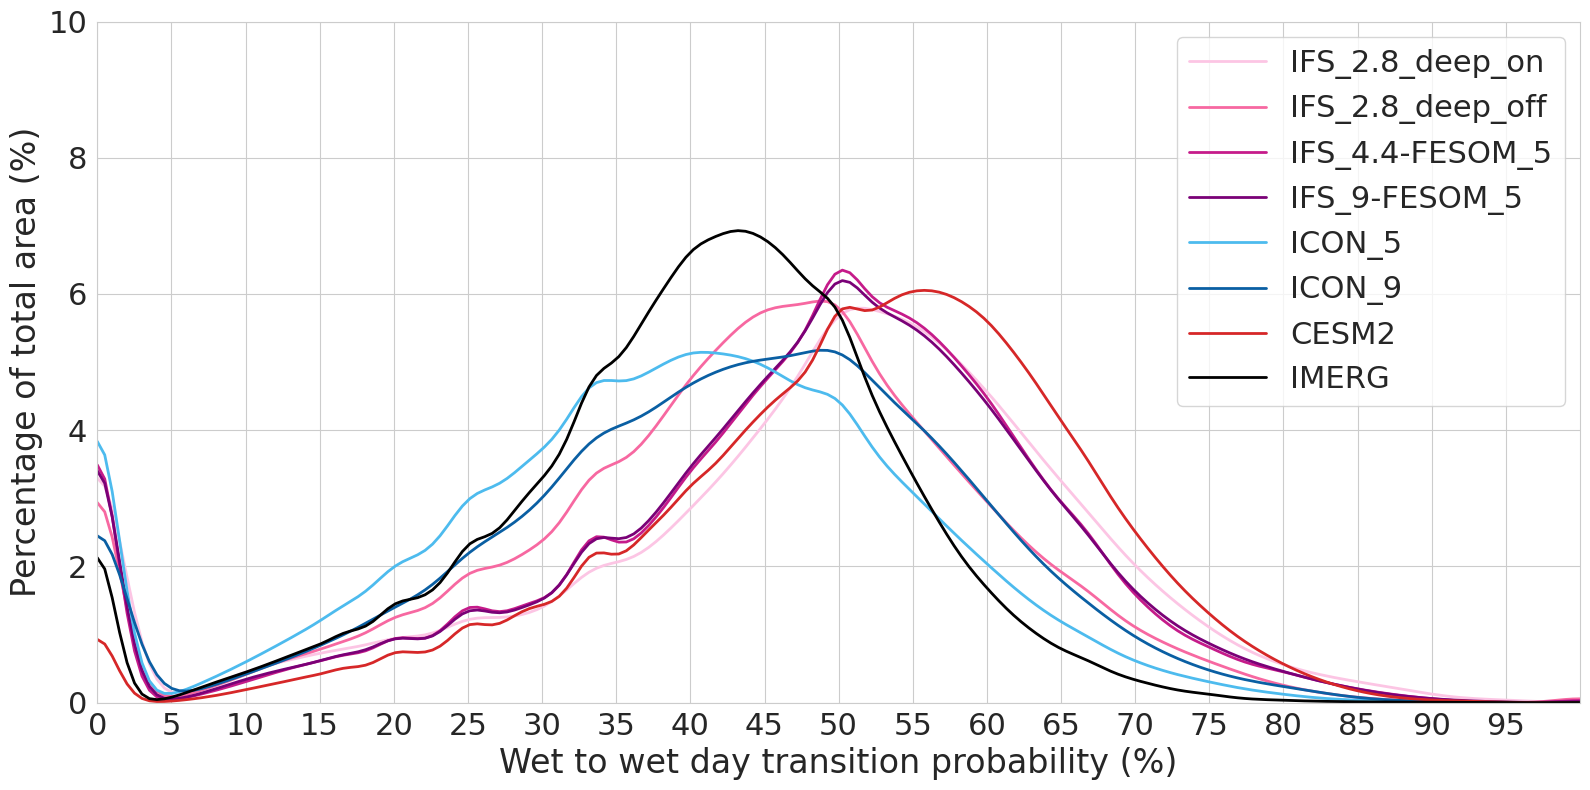

In [16]:
#with weights

# 1) Common x-range + bin width
xmin, xmax = 0, 100
bin_width  = 2.0


# For equal-area grids: weights = 1
def ones_like_da(da):
    return xr.ones_like(da)

#datasets = [
#    # IFS/ICON: equal-area → uniform weights
#    (ifs_on_land_WW,       ones_like_da(ifs_on_land_WW),       '#D73027', 'IFS_2.8_deep_on'),
#    (ifs_off_land_WW,      ones_like_da(ifs_off_land_WW),      '#FC8D59', 'IFS_2.8_deep_off'),
#    (ifs_cycle3_land_WW,   ones_like_da(ifs_cycle3_land_WW),   '#91BFDB', 'IFS_4.4-FESOM_5'),
#    (ifs_cycle4_land_WW,   ones_like_da(ifs_cycle4_land_WW),   '#4575B4', 'IFS_9-FESOM_5'),
#    (icon_cycle3_land_WW,  ones_like_da(icon_cycle3_land_WW),  '#9467BD', 'ICON_5'),
#    (icon_cycle4_land_WW,  ones_like_da(icon_cycle4_land_WW),  '#C5B0D5', 'ICON_9'),

#    # CESM2 & IMERG: area weights from above
#    (cesm2_land_WW,        w_cesm2_land_WW,                    '#E6AB02', 'CESM2'),
#    (imerg_land_WW,        w_imerg_land_WW,                    'k',       'IMERG'),
#]

datasets = [
    # IFS/ICON: equal-area → uniform weights
    (ifs_on_land_WW,       ones_like_da(ifs_on_land_WW),       '#FCC5E4', 'IFS_2.8_deep_on'),
    (ifs_off_land_WW,      ones_like_da(ifs_off_land_WW),      '#F768A1', 'IFS_2.8_deep_off'),
    (ifs_cycle3_land_WW,   ones_like_da(ifs_cycle3_land_WW),   '#C51B8A', 'IFS_4.4-FESOM_5'),
    (ifs_cycle4_land_WW,   ones_like_da(ifs_cycle4_land_WW),   '#7A0177', 'IFS_9-FESOM_5'),
    (icon_cycle3_land_WW,  ones_like_da(icon_cycle3_land_WW),  '#4DBBEE', 'ICON_5'),
    (icon_cycle4_land_WW,  ones_like_da(icon_cycle4_land_WW),  '#0A5FA3', 'ICON_9'),

    # CESM2 & IMERG: area weights from above
    (cesm2_land_WW,        w_cesm2_land_WW,                    '#D62728', 'CESM2'),
    (imerg_land_WW,        w_imerg_land_WW,                    '#000000',       'IMERG'),
]


plt.figure(figsize=(16, 8))
sns.set_style("whitegrid")
plt.rc('axes', titlesize=22)
plt.rc('axes', labelsize=18)

for data_da, wts_da, color, label in datasets:
    x = data_da.values.ravel()
    w = wts_da.values.ravel()

    sns.kdeplot(
        x=x,
        weights=w,
        bw_adjust=2.0,
        clip=(xmin, xmax),
        common_norm=False,
        fill=False,
        linewidth=2.0,
        color=color,
        label=label
    )

# 4) Rescale each line from density → percent per 0.5% bin
ax = plt.gca()
for line in ax.get_lines():
    x_vals, y_vals = line.get_data()
    y_scaled = y_vals * 100 * bin_width
    line.set_data(x_vals, y_scaled)

# 5) Labels, limits, legend
xl = 'Wet to wet day transition probability (%)'
ax.set_ylim(0, 10)
plt.xlabel(xl, fontsize=24)

plt.ylabel('Percentage of total area (%)', fontsize=24)


plt.xlim(xmin, xmax)
plt.tick_params(axis='both', which='major', labelsize=22)

xticks = np.arange(xmin, xmax, 5)
ax.set_xticks(xticks)

# build a list of Line2D handles matching your plotted lines
legend_handles = [
    Line2D([0], [0], color=color, linewidth=2.0)
    for *_, color, _ in datasets
]
# extract the labels out of your datasets tuple
legend_labels = [label for *_, _, label in datasets]

# then call legend with those handles
plt.legend(
    legend_handles,
    legend_labels,
    loc='upper right',
    prop={'size': 22},
    bbox_to_anchor=(1.0, 1.0),
    handlelength=2.5  # longer lines in legend if you like
)

plt.tight_layout()
plt.savefig('/home/jwille/images/global_paper/mid_lat_land_markov_WW_histo.pdf', format='pdf',bbox_inches='tight')

plt.show()

In [17]:
print(np.median(imerg_land_WD))


58.18181818181818


In [18]:
print(np.median(cesm2_land_WD))

47.05882352941176


In [19]:
print(np.median(ifs_off_land_WD))

55.172413793103445


In [20]:
print(np.median(ifs_on_land_WD))

50.0


In [21]:
print(np.median(icon_cycle4_land_WD))

56.666666666666664


In [22]:
print(np.median(icon_cycle3_land_WD))

60.71428571428571


In [23]:
print(np.median(ifs_cycle3_land_WD))

50.0


In [33]:
print(np.median(ifs_cycle4_land_WD))

50.63291139240506


## WD

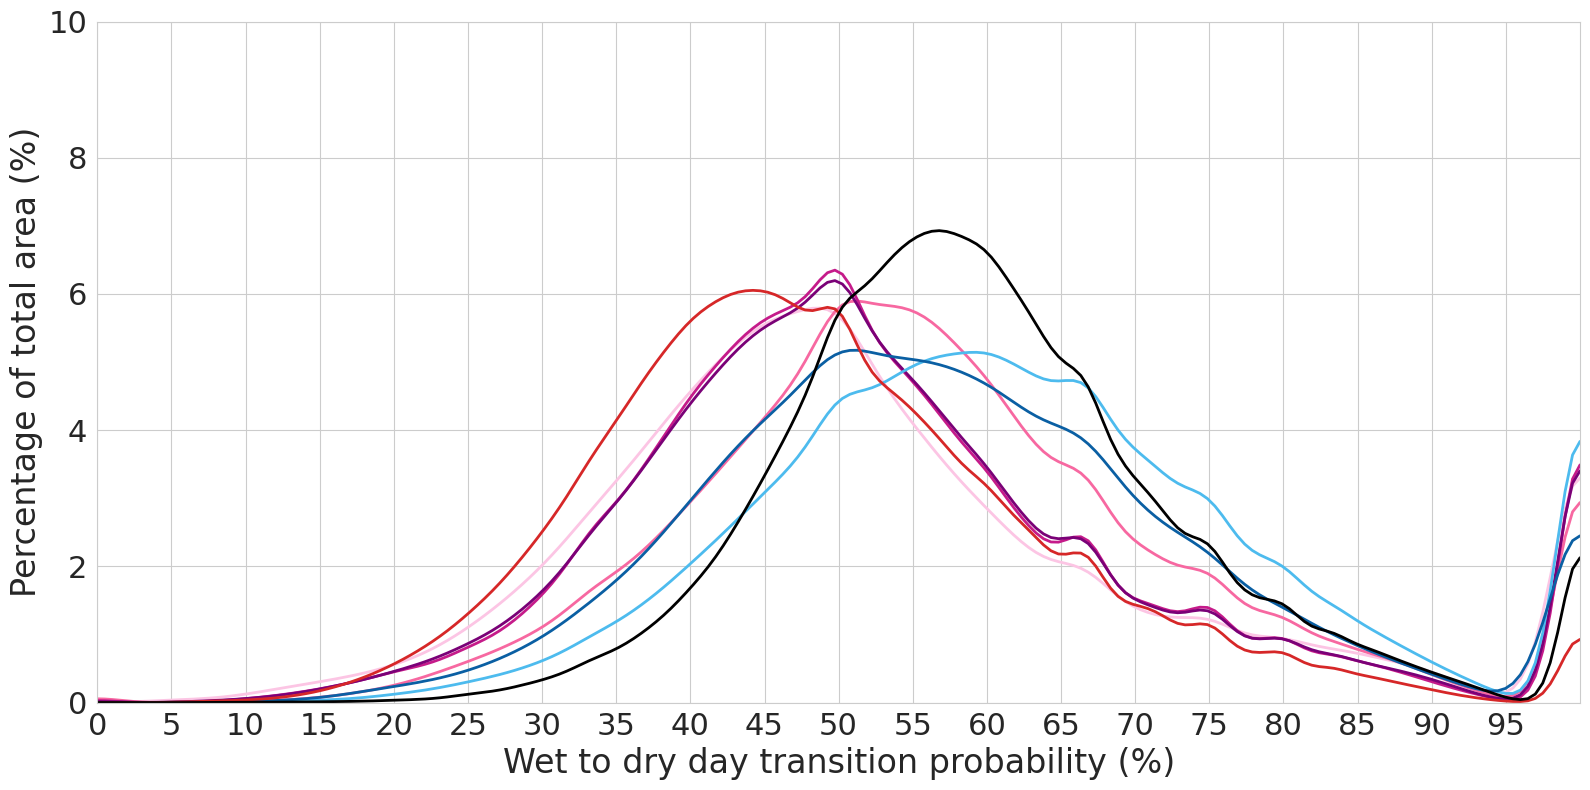

In [24]:
#with weights

# 1) Common x-range + bin width
xmin, xmax = 0, 100
bin_width  = 2.0


# For equal-area grids: weights = 1
def ones_like_da(da):
    return xr.ones_like(da)


datasets = [
    # IFS/ICON: equal-area → uniform weights
    (ifs_on_land_WD,       ones_like_da(ifs_on_land_WD),       '#FCC5E4', 'IFS_2.8_deep_on'),
    (ifs_off_land_WD,      ones_like_da(ifs_off_land_WD),      '#F768A1', 'IFS_2.8_deep_off'),
    (ifs_cycle3_land_WD,   ones_like_da(ifs_cycle3_land_WD),   '#C51B8A', 'IFS_4.4-FESOM_5'),
    (ifs_cycle4_land_WD,   ones_like_da(ifs_cycle4_land_WD),   '#7A0177', 'IFS_9-FESOM_5'),
    (icon_cycle3_land_WD,  ones_like_da(icon_cycle3_land_WD),  '#4DBBEE', 'ICON_5'),
    (icon_cycle4_land_WD,  ones_like_da(icon_cycle4_land_WD),  '#0A5FA3', 'ICON_9'),

    # CESM2 & IMERG: area weights from above
    (cesm2_land_WD,        w_cesm2_land_WD,                    '#D62728', 'CESM2'),
    (imerg_land_WD,        w_imerg_land_WD,                    '#000000',       'IMERG'),
]



plt.figure(figsize=(16, 8))
sns.set_style("whitegrid")
plt.rc('axes', titlesize=22)
plt.rc('axes', labelsize=18)

for data_da, wts_da, color, label in datasets:
    x = data_da.values.ravel()
    w = wts_da.values.ravel()

    sns.kdeplot(
        x=x,
        weights=w,
        bw_adjust=2.0,
        clip=(xmin, xmax),
        common_norm=False,
        fill=False,
        linewidth=2.0,
        color=color,
        label=label
    )

# 4) Rescale each line from density → percent per 0.5% bin
ax = plt.gca()
for line in ax.get_lines():
    x_vals, y_vals = line.get_data()
    y_scaled = y_vals * 100 * bin_width
    line.set_data(x_vals, y_scaled)

# 5) Labels, limits, legend
xl = 'Wet to dry day transition probability (%)'
ax.set_ylim(0, 10)
plt.xlabel(xl, fontsize=24)

plt.ylabel('Percentage of total area (%)', fontsize=24)


plt.xlim(xmin, xmax)
plt.tick_params(axis='both', which='major', labelsize=22)

xticks = np.arange(xmin, xmax, 5)
ax.set_xticks(xticks)

# build a list of Line2D handles matching your plotted lines
legend_handles = [
    Line2D([0], [0], color=color, linewidth=2.0)
    for *_, color, _ in datasets
]
# extract the labels out of your datasets tuple
legend_labels = [label for *_, _, label in datasets]

# then call legend with those handles
#plt.legend(
#    legend_handles,
#    legend_labels,
#    loc='upper right',
#    prop={'size': 22},
#    bbox_to_anchor=(1.0, 1.0),
#    handlelength=2.5  # longer lines in legend if you like
#)

plt.tight_layout()
plt.savefig('/home/jwille/images/global_paper/mid_lat_land_markov_WD_histo.pdf', format='pdf',bbox_inches='tight')

plt.show()

In [25]:
print(np.median(imerg_land_DW))


21.705426356589147


In [26]:
print(np.median(cesm2_land_DW))

23.88059701492537


In [27]:
print(np.median(ifs_off_land_DW))

19.696969696969695


In [28]:
print(np.median(ifs_on_land_DW))

18.4


In [29]:
print(np.median(icon_cycle4_land_DW))

20.43010752688172


In [30]:
print(np.median(icon_cycle3_land_DW))

16.551724137931036


In [31]:
print(np.median(ifs_cycle3_land_DW))

18.51851851851852


In [34]:
print(np.median(ifs_cycle4_land_DW))

18.51851851851852


In [38]:
print(ifs_cycle3_land_DW.mean())

<xarray.DataArray 'P_DW' ()> Size: 8B
array(18.64003921)
Coordinates:
    time     datetime64[ns] 8B 2020-01-15


In [39]:
print(ifs_cycle4_land_DW.mean())

<xarray.DataArray 'P_DW' ()> Size: 8B
array(18.31562209)


## DW

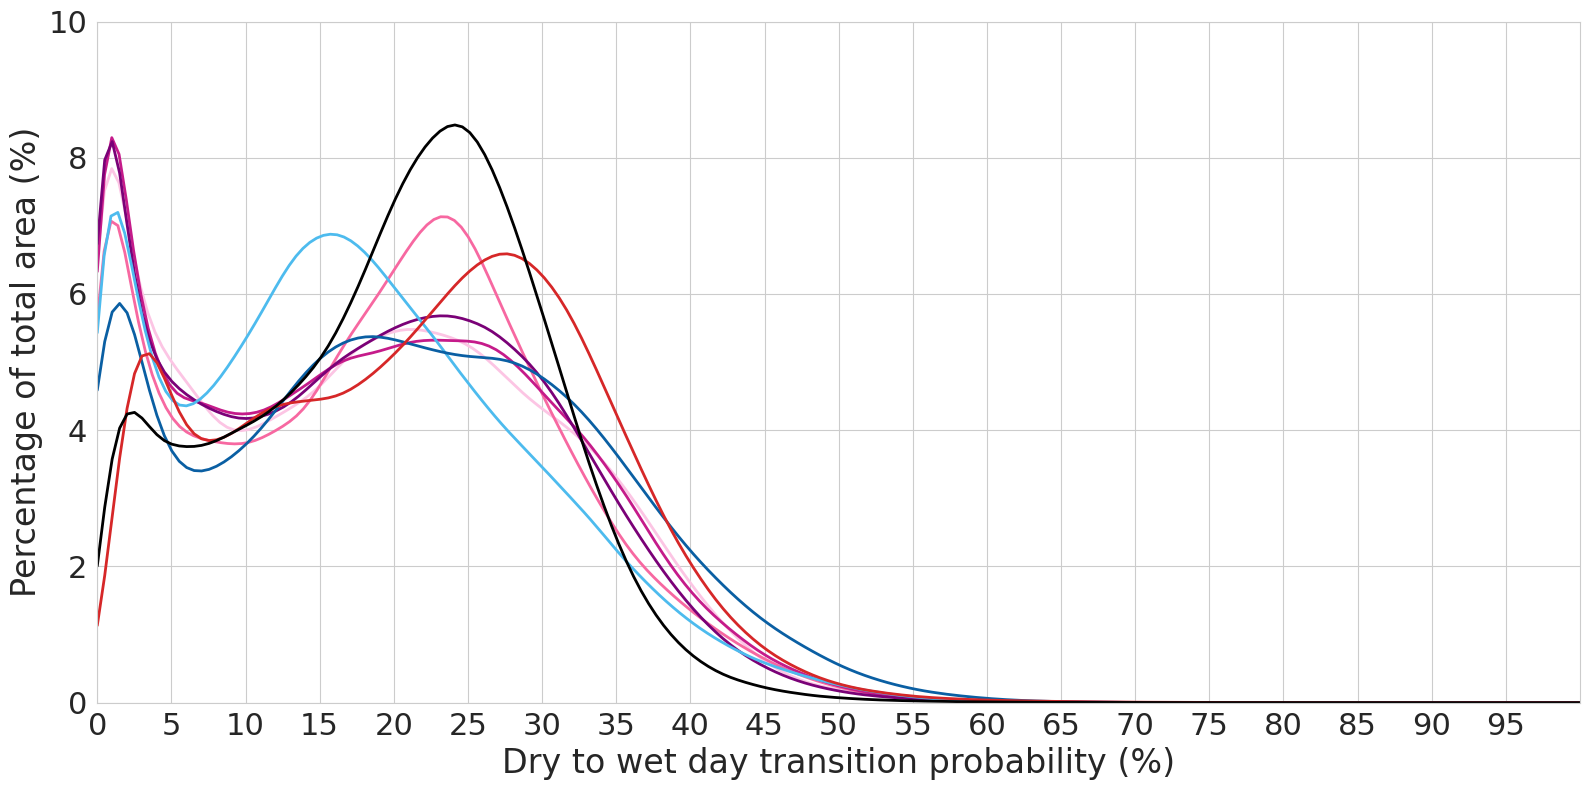

In [35]:
#with weights

# 1) Common x-range + bin width
xmin, xmax = 0, 100
bin_width  = 2.0


# For equal-area grids: weights = 1
def ones_like_da(da):
    return xr.ones_like(da)


datasets = [
    # IFS/ICON: equal-area → uniform weights
    (ifs_on_land_DW,       ones_like_da(ifs_on_land_DW),       '#FCC5E4', 'IFS_2.8_deep_on'),
    (ifs_off_land_DW,      ones_like_da(ifs_off_land_DW),      '#F768A1', 'IFS_2.8_deep_off'),
    (ifs_cycle3_land_DW,   ones_like_da(ifs_cycle3_land_DW),   '#C51B8A', 'IFS_4.4-FESOM_5'),
    (ifs_cycle4_land_DW,   ones_like_da(ifs_cycle4_land_DW),   '#7A0177', 'IFS_9-FESOM_5'),
    (icon_cycle3_land_DW,  ones_like_da(icon_cycle3_land_DW),  '#4DBBEE', 'ICON_5'),
    (icon_cycle4_land_DW,  ones_like_da(icon_cycle4_land_DW),  '#0A5FA3', 'ICON_9'),

    # CESM2 & IMERG: area weights from above
    (cesm2_land_DW,        w_cesm2_land_DW,                    '#D62728', 'CESM2'),
    (imerg_land_DW,        w_imerg_land_DW,                    '#000000',       'IMERG'),
]


plt.figure(figsize=(16, 8))
sns.set_style("whitegrid")
plt.rc('axes', titlesize=22)
plt.rc('axes', labelsize=18)

for data_da, wts_da, color, label in datasets:
    x = data_da.values.ravel()
    w = wts_da.values.ravel()

    sns.kdeplot(
        x=x,
        weights=w,
        bw_adjust=2.0,
        clip=(xmin, xmax),
        common_norm=False,
        fill=False,
        linewidth=2.0,
        color=color,
        label=label
    )

# 4) Rescale each line from density → percent per 0.5% bin
ax = plt.gca()
for line in ax.get_lines():
    x_vals, y_vals = line.get_data()
    y_scaled = y_vals * 100 * bin_width
    line.set_data(x_vals, y_scaled)

# 5) Labels, limits, legend
xl = 'Dry to wet day transition probability (%)'
ax.set_ylim(0, 10)
plt.xlabel(xl, fontsize=24)

plt.ylabel('Percentage of total area (%)', fontsize=24)


plt.xlim(xmin, xmax)
plt.tick_params(axis='both', which='major', labelsize=22)

xticks = np.arange(xmin, xmax, 5)
ax.set_xticks(xticks)

# build a list of Line2D handles matching your plotted lines
legend_handles = [
    Line2D([0], [0], color=color, linewidth=2.0)
    for *_, color, _ in datasets
]
# extract the labels out of your datasets tuple
legend_labels = [label for *_, _, label in datasets]

# then call legend with those handles
#plt.legend(
#    legend_handles,
#    legend_labels,
#    loc='upper right',
#    prop={'size': 22},
#    bbox_to_anchor=(1.0, 1.0),
#    handlelength=2.5  # longer lines in legend if you like
#)

plt.tight_layout()
plt.savefig('/home/jwille/images/global_paper/mid_lat_land_markov_DW_histo.pdf', format='pdf',bbox_inches='tight')

plt.show()

## DD

In [ ]:
#with weights

# 1) Common x-range + bin width
xmin, xmax = 0, 100
bin_width  = 2.0


# For equal-area grids: weights = 1
def ones_like_da(da):
    return xr.ones_like(da)

datasets = [
    # IFS/ICON: equal-area → uniform weights
    (ifs_on_land_DD,       ones_like_da(ifs_on_land_DD),       '#FCC5E4', 'IFS_2.8_deep_on'),
    (ifs_off_land_DD,      ones_like_da(ifs_off_land_DD),      '#F768A1', 'IFS_2.8_deep_off'),
    (ifs_cycle3_land_DD,   ones_like_da(ifs_cycle3_land_DD),   '#C51B8A', 'IFS_4.4-FESOM_5'),
    (ifs_cycle4_land_DD,   ones_like_da(ifs_cycle4_land_DD),   '#7A0177', 'IFS_9-FESOM_5'),
    (icon_cycle3_land_DD,  ones_like_da(icon_cycle3_land_DD),  '#4DBBEE', 'ICON_5'),
    (icon_cycle4_land_DD,  ones_like_da(icon_cycle4_land_DD),  '#0A5FA3', 'ICON_9'),

    # CESM2 & IMERG: area weights from above
    (cesm2_land_DD,        w_cesm2_land_DD,                    '#D62728', 'CESM2'),
    (imerg_land_DD,        w_imerg_land_DD,                    '#000000',       'IMERG'),
]


plt.figure(figsize=(16, 8))
sns.set_style("whitegrid")
plt.rc('axes', titlesize=22)
plt.rc('axes', labelsize=18)

for data_da, wts_da, color, label in datasets:
    x = data_da.values.ravel()
    w = wts_da.values.ravel()

    sns.kdeplot(
        x=x,
        weights=w,
        bw_adjust=2.0,
        clip=(xmin, xmax),
        common_norm=False,
        fill=False,
        linewidth=2.0,
        color=color,
        label=label
    )

# 4) Rescale each line from density → percent per 0.5% bin
ax = plt.gca()
for line in ax.get_lines():
    x_vals, y_vals = line.get_data()
    y_scaled = y_vals * 100 * bin_width
    line.set_data(x_vals, y_scaled)

# 5) Labels, limits, legend
xl = 'Dry to dry day transition probability (%)'
ax.set_ylim(0, 10)
plt.xlabel(xl, fontsize=24)

plt.ylabel('Percentage of total area (%)', fontsize=24)


plt.xlim(xmin, xmax)
plt.tick_params(axis='both', which='major', labelsize=22)

xticks = np.arange(xmin, xmax, 5)
ax.set_xticks(xticks)

# build a list of Line2D handles matching your plotted lines
legend_handles = [
    Line2D([0], [0], color=color, linewidth=2.0)
    for *_, color, _ in datasets
]
# extract the labels out of your datasets tuple
legend_labels = [label for *_, _, label in datasets]

# then call legend with those handles
#plt.legend(
#    legend_handles,
#    legend_labels,
#    loc='upper left',
#    prop={'size': 22},
#    handlelength=2.5  # longer lines in legend if you like
#)

plt.tight_layout()
plt.savefig('/home/jwille/images/global_paper/mid_lat_land_markov_DD_histo.pdf', format='pdf',bbox_inches='tight')

plt.show()